# Phase 2 — Bayesian edge tracker

**Purpose.** Phase 1 showed that every result depends on two borrowed
numbers: a 23% win rate and an 8R average winner. This notebook estimates
**your** numbers from **your** trade log, and says how sure you can be.

**Mission.** Answer three questions:

1. What is my win rate, and how uncertain is it?
2. What is my expectancy in R, and what is the chance it is above zero?
3. Does the evidence support full risk (1R), half risk (0.5R), or a pause?

**The idea, in one line.**

> belief after the trades = belief before the trades × what the trades say

The belief before is the **prior** (here: the borrowed 23% and 8R, held
loosely). What the trades say is the **likelihood**. The result is the
**posterior**. With few trades the prior dominates. With many trades your
own data takes over.

**Read this first.** The notebook ships with `sample_trade_log.csv`.
Those 40 trades are **made up for practice**; they are not real and not
yours. Point `TRADE_LOG` at your own file to get your own answer.
Study tool, not advice.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import beta as beta_dist

import lab_style as ls
import bayes_edge as be

ls.use_lab_style()

In [2]:
# ============================================================
# KEY IN HERE
# ============================================================
TRADE_LOG = "sample_trade_log.csv"   # your CSV: a column R, oldest trade first
                                     # (or the columns pnl and risk_dollars)

PRIOR_WIN_RATE     = 0.23   # borrowed starting belief
PRIOR_WIN_STRENGTH = 20     # the belief is worth this many imaginary trades
PRIOR_AVG_WIN_R    = 8.0    # borrowed starting belief
PRIOR_SIZE_STRENGTH = 5     # worth this many imaginary winners (20 trades x 23%)

prior = be.Prior(win_rate=PRIOR_WIN_RATE, win_strength=PRIOR_WIN_STRENGTH,
                 avg_win_R=PRIOR_AVG_WIN_R, size_strength=PRIOR_SIZE_STRENGTH)

## Step 1 — Load the trade log

In [3]:
log = be.load_trade_log(TRADE_LOG)
R = log["R"].to_numpy()
n_trades, n_wins = len(R), int(np.sum(R > 0))
n_losses = n_trades - n_wins

print(f"Trades: {n_trades}   wins: {n_wins}   losses: {n_losses}")
print(f"Raw win rate      : {n_wins / n_trades:.1%}")
print(f"Raw average winner: {R[R > 0].mean():.2f} R")
print(f"Raw average loser : {R[R <= 0].mean():.2f} R")
print(f"Raw expectancy    : {R.mean():+.2f} R per trade")
log.tail(8)

Trades: 40   wins: 8   losses: 32
Raw win rate      : 20.0%
Raw average winner: 2.47 R
Raw average loser : -0.97 R
Raw expectancy    : -0.28 R per trade


,date,ticker,R
32,2026-08-28,SAMPLE33,0.74
33,2026-09-01,SAMPLE34,2.51
34,2026-09-03,SAMPLE35,-0.50
35,2026-09-07,SAMPLE36,-1.00
36,2026-09-09,SAMPLE37,-1.30
37,2026-09-11,SAMPLE38,2.79
38,2026-09-15,SAMPLE39,-1.30
39,2026-09-17,SAMPLE40,2.97


The raw numbers look exact. They are not: they come from a small sample.
A different 40 trades from the same trader would give different numbers.
The rest of the notebook measures that uncertainty.

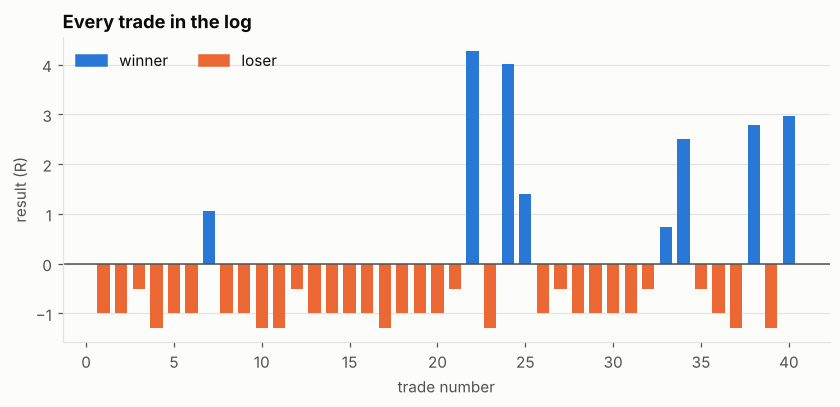

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
colors = np.where(R > 0, ls.BLUE, ls.ORANGE)
ax.bar(np.arange(1, n_trades + 1), R, color=colors, width=0.7)
ax.axhline(0, color=ls.TEXT_SOFT, lw=1)
ax.set_xlabel("trade number"); ax.set_ylabel("result (R)")
ax.set_title("Every trade in the log")
ax.legend(handles=[Patch(color=ls.BLUE, label="winner"),
                   Patch(color=ls.ORANGE, label="loser")], loc="upper left", ncol=2)
ax.grid(axis="x", visible=False)
plt.show()

## Step 2 — Bayes' rule by hand, on a grid

Take 501 candidate win rates from 0% to 100%. Three vectors of 501 numbers:

- `prior`: how believable each candidate is before the trades
- `likelihood`: how well each candidate explains the wins and losses seen
- `posterior = prior × likelihood`, entry by entry, then scaled to area 1

That entry-by-entry product is the whole of Bayes' rule.

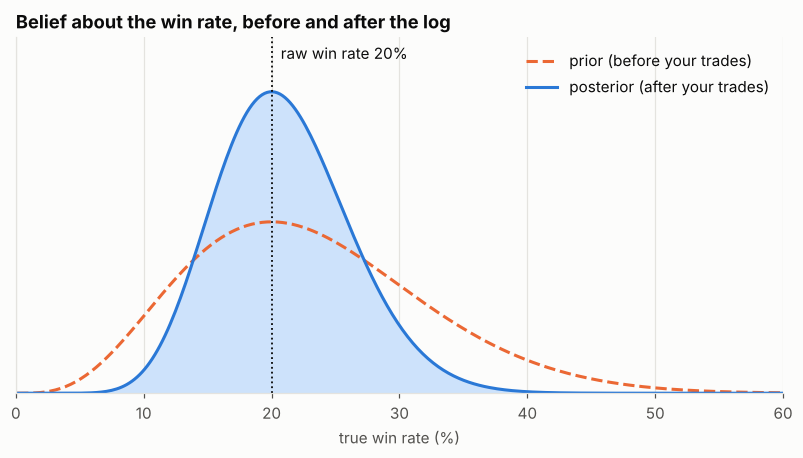

In [5]:
grid, prior_curve, post_curve = be.grid_posterior(n_wins, n_losses, prior)

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(100 * grid, prior_curve, color=ls.ORANGE, ls="--", label="prior (before your trades)")
ax.plot(100 * grid, post_curve, color=ls.BLUE, label="posterior (after your trades)")
ax.fill_between(100 * grid, post_curve, color=ls.BLUE_BAND_OUTER)
ax.set_ylim(0, post_curve.max() * 1.18)
ax.axvline(100 * n_wins / n_trades, color=ls.TEXT, lw=1.2, ls=":")
ax.annotate(f"raw win rate {n_wins / n_trades:.0%}",
            (100 * n_wins / n_trades, ax.get_ylim()[1] * 0.94),
            textcoords="offset points", xytext=(6, 0), color=ls.TEXT)
ax.set_xlim(0, 60); ax.set_xlabel("true win rate (%)"); ax.set_yticks([])
ax.set_title("Belief about the win rate, before and after the log")
ax.legend(loc="upper right")
plt.show()

The posterior is taller and narrower than the prior: the log added
information. It sits between the prior's centre and the raw win rate.

## Step 3 — The shortcut: just add the counts

For win or loss data the grid is not needed. The belief is a Beta
distribution, and updating it is addition:

> `a = prior wins + your wins`, `b = prior losses + your losses`

A prior of strength 20 centred on 23% counts as 4.6 imaginary wins and
15.4 imaginary losses.

In [6]:
a, b = be.win_rate_posterior(R, prior)
lo, mid, hi = beta_dist.ppf([0.05, 0.50, 0.95], a, b)

print(f"Prior     : Beta({prior.win_rate * prior.win_strength:.1f}, "
      f"{(1 - prior.win_rate) * prior.win_strength:.1f})")
print(f"Posterior : Beta({a:.1f}, {b:.1f})")
print(f"Win rate  : median {mid:.1%}, 90% credible interval {lo:.1%} to {hi:.1%}")
print(f"Break-even win rate at 8R payoff is 11.1%. "
      f"P(win rate > 11.1%) = {1 - beta_dist.cdf(1 / 9, a, b):.0%}")

Prior     : Beta(4.6, 15.4)
Posterior : Beta(12.6, 47.4)
Win rate  : median 20.7%, 90% credible interval 13.0% to 30.1%
Break-even win rate at 8R payoff is 11.1%. P(win rate > 11.1%) = 98%


## Chart — Belief narrows as trades arrive

The same update, replayed one trade at a time. The band is the 90% credible
interval. It starts wide (prior only) and narrows slowly.

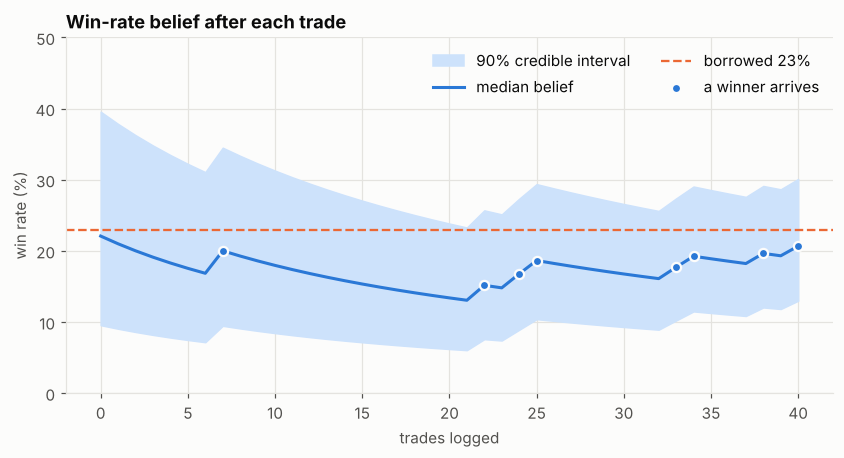

Width of the 90% interval: 30 points with no trades, 17 points after 40 trades.


In [7]:
steps = np.arange(n_trades + 1)
wins_so_far = np.concatenate([[0], np.cumsum(R > 0)])
a_t = prior.win_rate * prior.win_strength + wins_so_far
b_t = (1 - prior.win_rate) * prior.win_strength + (steps - wins_so_far)
band_lo, band_mid, band_hi = (100 * beta_dist.ppf(q, a_t, b_t) for q in (0.05, 0.5, 0.95))

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.fill_between(steps, band_lo, band_hi, color=ls.BLUE_BAND_OUTER, label="90% credible interval")
ax.plot(steps, band_mid, color=ls.BLUE, label="median belief")
ax.axhline(100 * prior.win_rate, color=ls.ORANGE, ls="--", lw=1.5, label="borrowed 23%")
win_idx = np.flatnonzero(R > 0) + 1
ax.scatter(win_idx, band_mid[win_idx], s=36, color=ls.BLUE, edgecolor=ls.SURFACE,
           linewidth=1.5, zorder=3, label="a winner arrives")
ax.set_xlabel("trades logged"); ax.set_ylabel("win rate (%)"); ax.set_ylim(0, 50)
ax.set_title("Win-rate belief after each trade"); ax.legend(loc="upper right", ncol=2)
plt.show()

print(f"Width of the 90% interval: {band_hi[0] - band_lo[0]:.0f} points with no trades, "
      f"{band_hi[-1] - band_lo[-1]:.0f} points after {n_trades} trades.")

## Step 4 — How big are the winners?

Win rate is half the edge. The other half is the average winner. Winner
sizes are skewed (a few very large), so the engine models their logarithm
as Normal and updates the mean and spread together. With few winners this
estimate stays wide.

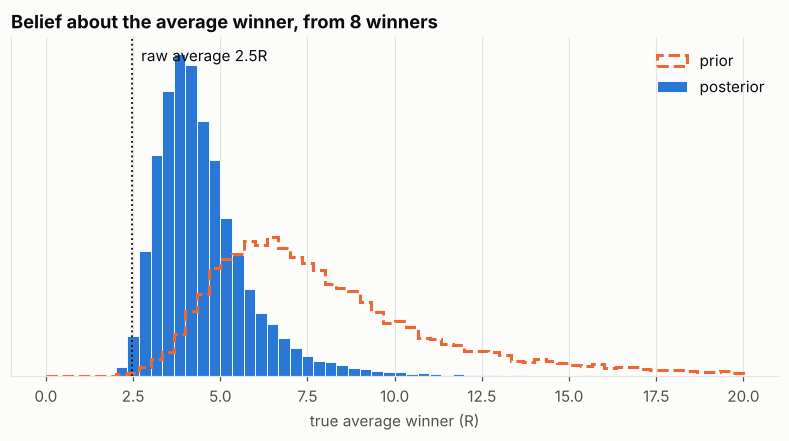

Average winner: median 4.2R, 90% credible interval 2.9R to 7.2R
Average loser used: 0.98R


In [8]:
edge = be.sample_edge(R, prior, draws=20_000, seed=0)
prior_only = be.sample_edge([], prior, draws=20_000, seed=0)

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 20, 61)
ax.hist(prior_only["avg_win_R"], bins=bins, density=True, histtype="step",
        color=ls.ORANGE, lw=2, ls="--", label="prior")
ax.hist(edge["avg_win_R"], bins=bins, density=True, color=ls.BLUE,
        edgecolor=ls.SURFACE, linewidth=0.6, label="posterior")
ax.axvline(R[R > 0].mean(), color=ls.TEXT, lw=1.2, ls=":")
ax.annotate(f"raw average {R[R > 0].mean():.1f}R", (R[R > 0].mean(), ax.get_ylim()[1] * 0.93),
            textcoords="offset points", xytext=(6, 0), color=ls.TEXT)
ax.set_xlabel("true average winner (R)"); ax.set_yticks([])
ax.set_title(f"Belief about the average winner, from {n_wins} winners")
ax.legend(loc="upper right")
plt.show()

q = edge["avg_win_R"].quantile([0.05, 0.5, 0.95])
print(f"Average winner: median {q[0.5]:.1f}R, 90% credible interval "
      f"{q[0.05]:.1f}R to {q[0.95]:.1f}R")
print(f"Average loser used: {edge['avg_loss_R'].iloc[0]:.2f}R")

## Step 5 — Expectancy: is there an edge?

Each of 20,000 draws picks one plausible win rate and one plausible average
winner, and computes

> `expectancy = win rate × average winner − loss rate × average loser`

The histogram of those draws is the belief about your edge.

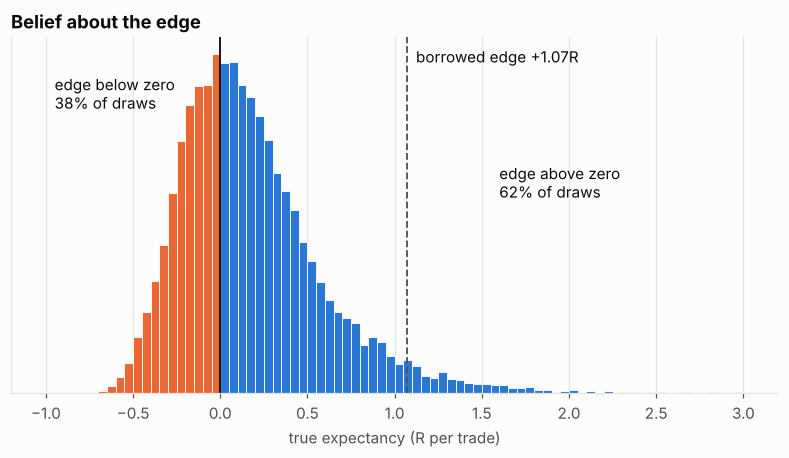

Expectancy: median +0.11R, 90% credible interval -0.36R to +0.98R
P(expectancy > 0)             = 62%
P(expectancy >= borrowed 1.07R) = 4%


In [9]:
exp = edge["expectancy_R"]
p_positive = float(np.mean(exp > 0))
borrowed = 0.23 * 8.0 - 0.77 * 1.0

fig, ax = plt.subplots(figsize=(9, 4.2))
bins = np.linspace(-1, 3, 81)
counts, edges, patches = ax.hist(exp, bins=bins, color=ls.BLUE,
                                 edgecolor=ls.SURFACE, linewidth=0.6)
for patch, left in zip(patches, edges[:-1]):
    if left < 0:
        patch.set_facecolor(ls.ORANGE)
ax.axvline(0, color=ls.TEXT, lw=1.2)
ax.axvline(borrowed, color=ls.TEXT_SOFT, lw=1.2, ls="--")
top = ax.get_ylim()[1]
ax.annotate(f"borrowed edge {borrowed:+.2f}R", (borrowed, top * 0.93),
            textcoords="offset points", xytext=(6, 0), color=ls.TEXT)
ax.annotate(f"edge below zero\n{1 - p_positive:.0%} of draws", (-0.95, top * 0.80), color=ls.TEXT)
ax.annotate(f"edge above zero\n{p_positive:.0%} of draws", (1.6, top * 0.55), color=ls.TEXT)
ax.set_xlabel("true expectancy (R per trade)"); ax.set_yticks([])
ax.set_title("Belief about the edge")
plt.show()

q = exp.quantile([0.05, 0.5, 0.95])
print(f"Expectancy: median {q[0.5]:+.2f}R, 90% credible interval "
      f"{q[0.05]:+.2f}R to {q[0.95]:+.2f}R")
print(f"P(expectancy > 0)             = {p_positive:.0%}")
print(f"P(expectancy >= borrowed {borrowed:.2f}R) = {np.mean(exp >= borrowed):.0%}")

## Step 6 — The sizing decision

Rule E3 says probe at half size, go full only after the probe works. Here
the same idea is applied to the whole method, with numbers:

| Evidence | Risk per trade |
|---|---|
| fewer than 30 trades logged | 0.5R |
| P(edge > 0) at or above 90% | 1R |
| P(edge > 0) between 60% and 90% | 0.5R |
| P(edge > 0) below 60% | pause and review |

The 30, 60% and 90% are starting thresholds. Tune them in `sizing_decision`.

In [10]:
setting, reason = be.sizing_decision(p_positive, n_trades)
print(f"RISK SETTING: {setting}")
print(reason)

RISK SETTING: 0.5R
P(edge > 0) = 62%, between 60% and 90%. Stay at half risk.


## Chart — How many trades until the log can be trusted?

The width of the 90% interval for the win rate, if the true win rate is 23%,
against the number of trades logged. This uses no prior: it shows what data
alone can tell you.

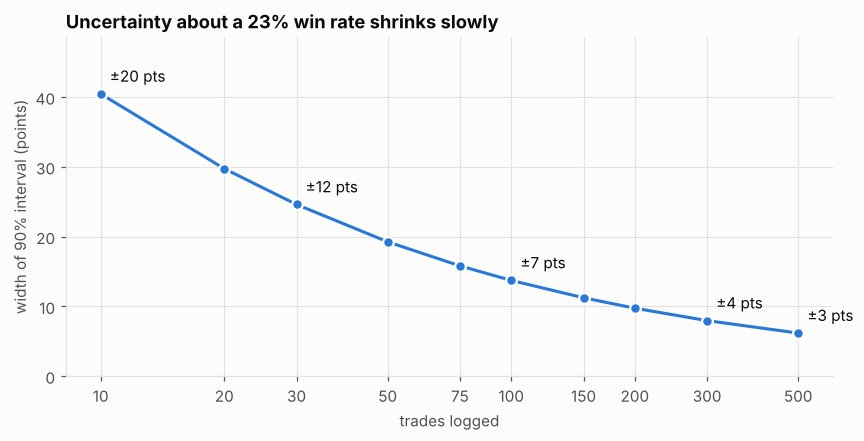

In [11]:
n_grid = np.array([10, 20, 30, 50, 75, 100, 150, 200, 300, 500])
width = [100 * np.subtract(*beta_dist.ppf([0.95, 0.05], 0.23 * n + 1, 0.77 * n + 1))
         for n in n_grid]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(n_grid, width, color=ls.BLUE, marker="o", markersize=7,
        markeredgecolor=ls.SURFACE, markeredgewidth=1.5)
for n, w in zip(n_grid, width):
    if n in (10, 30, 100, 300, 500):
        ax.annotate(f"±{w / 2:.0f} pts", (n, w), textcoords="offset points",
                    xytext=(6, 8), color=ls.TEXT)
ax.set_xscale("log"); ax.set_xticks(n_grid); ax.set_xticklabels(n_grid)
ax.minorticks_off(); ax.set_ylim(0, max(width) * 1.2)
ax.set_xlabel("trades logged"); ax.set_ylabel("width of 90% interval (points)")
ax.set_title("Uncertainty about a 23% win rate shrinks slowly")
plt.show()

To halve the uncertainty you need four times the trades (the square-root
rule again, as in the option band of your calculator). Thirty trades cannot
tell a 15% trader from a 30% trader.

## Check — How much does the prior matter?

If the answer changes a lot with prior strength, the log is still too small
and the prior is doing the talking.

In [12]:
rows = {}
for strength in [2, 20, 100]:
    p = be.Prior(win_rate=PRIOR_WIN_RATE, win_strength=strength,
                 avg_win_R=PRIOR_AVG_WIN_R, size_strength=strength / 4)
    e = be.sample_edge(R, p, draws=20_000, seed=0)
    rows[f"prior strength {strength}"] = {
        "Win rate, median %": 100 * e["win_rate"].median(),
        "Avg winner, median R": e["avg_win_R"].median(),
        "Expectancy, median R": e["expectancy_R"].median(),
        "P(edge > 0) %": 100 * np.mean(e["expectancy_R"] > 0),
    }
sens = pd.DataFrame(rows).T.round(2)
print(sens.to_string())

spread = sens["P(edge > 0) %"].max() - sens["P(edge > 0) %"].min()
if spread > 20:
    print(f"\nP(edge > 0) moves {spread:.0f} points across prior strengths.")
    print("The prior is doing the talking. Treat the verdict as unproven "
          "and keep logging trades.")
else:
    print(f"\nP(edge > 0) moves only {spread:.0f} points. The log dominates.")

                    Win rate, median %  Avg winner, median R  Expectancy, median R  P(edge > 0) %
prior strength 2                 19.64                  2.70                 -0.25          20.22
prior strength 20                20.71                  4.23                  0.11          62.48
prior strength 100               22.03                  6.45                  0.66          98.83

P(edge > 0) moves 79 points across prior strengths.
The prior is doing the talking. Treat the verdict as unproven and keep logging trades.


## What this notebook shows

The figures below are for the **made-up sample log** (40 trades, 8 winners)
with the default prior. Your own log will give different numbers.

1. **Raw numbers mislead.** The raw win rate is 20.0%. The belief is a range:
   13% to 30% (90% credible interval).
2. **Winner size is the weak spot.** Eight winners average 2.5R. The belief
   about the true average winner runs from 2.9R to 7.2R, still pulled up by
   the borrowed 8R.
3. **The edge is unproven.** Median expectancy is +0.11R, and P(edge > 0) is
   62%. The chance that this trader matches the borrowed +1.07R is 4%.
4. **The decision is half risk.** 62% is between 60% and 90%, so 0.5R.
5. **The prior still dominates.** P(edge > 0) moves from 20% to 99% as the
   prior goes from weak to strong. Forty trades are too few to settle it.
6. **Evidence is slow.** About 100 trades give ±7 points on the win rate,
   300 trades give ±4 points.

## What the tracker does not model

- Trades are treated as independent and the edge as constant. Real edges
  change with the market regime (Phase 4 looks at regimes).
- The average loser is a blended point value, without its own uncertainty.
- A log that leaves out losing trades gives a wrong answer. Log every trade.

## Exercises

1. Set `PRIOR_WIN_STRENGTH = 2`, then `100`. Watch the two curves in Step 2.
2. Delete the last 20 rows of the sample log. How does P(edge > 0) change?
3. Add five rows with `R = 12` to the log. What does one big winner do to
   the average-winner belief?
4. Replace `TRADE_LOG` with your own file. Compare your posterior with the
   borrowed 23% and 8R.
5. In `bayes_edge.py`, read `grid_posterior`. Which line is Bayes' rule?

Next: Phase 3 feeds these draws into the Phase 1 engine, so every simulated
future uses a plausible edge of yours, not a fixed borrowed one.